# ATAC-seq Performance Benchmarking Report

The goal here is to analyse the performance of the cluster prediction model on ATAC-seq data.

In [2]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
# Load original sp data, atac + rna data after tangram, and the integrated data after seurat

# data/shareseq/c_sp_ad.h5ad
# data/tangram_output/sp_atac.h5ad
# data/tangram_output/sp_rna.h5ad
# data/sp_integrated_rna.h5ad

sp_ad = sc.read_h5ad("../data/shareseq/c_sp_ad.h5ad")
sp_atac = sc.read_h5ad("../data/tangram_output/sp_atac.h5ad")
sp_rna = sc.read_h5ad("../data/tangram_output/sp_rna.h5ad")
sp_integrated = sc.read_h5ad("../data/sp_integrated_rna.h5ad")

# data/shareseq_processed/c_atac_ad.h5ad
# data/shareseq_processed/c_sc_ad.h5ad

c_atac = sc.read_h5ad("../data/shareseq_processed/c_atac_ad.h5ad")
c_sc = sc.read_h5ad("../data/shareseq_processed/c_sc_ad.h5ad")

In [5]:
sp_ad.obs

,sample_id,slice_id,class_label,subclass,label,cell_id,centroid_x,centroid_y,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_5_genes,pct_counts_in_top_10_genes,pct_counts_in_top_50_genes
0,mouse1_sample4,mouse1_slice201,Glutamatergic,L5 ET,L5_ET_1,100019180101435853096549957382098546223,-6657.531936,1287.999918,85,4.454347,360.930664,5.891453,33.837642,50.454340,90.373314
3,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_2,100184805681957082256155880479666324162,-5940.450147,2866.995172,50,3.931826,236.033554,5.468202,34.684545,53.360841,100.000002
4,mouse1_sample4,mouse1_slice201,Other,OPC,OPC,100216539013568881378794340651675682089,-5679.370659,2502.973625,71,4.276666,468.888489,6.152495,43.234190,55.360852,93.059509
5,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_5,100232131524329250714605674212130911534,-6521.100329,1766.361327,70,4.262680,158.948608,5.074852,28.001558,44.762292,92.013161
6,mouse1_sample4,mouse1_slice201,Other,Endo,Endo,100235206899064056442210326904524278857,-5450.243352,1313.363304,49,3.912023,244.696274,5.504096,59.589565,73.866232,100.000002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6213,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_3,99830153011502724453730986477634907464,-6442.106111,2054.697518,65,4.189655,234.057556,5.459830,32.956630,47.846825,94.808204
6214,mouse1_sample4,mouse1_slice201,Glutamatergic,L5/6 NP,L56_NP_2,99890643086171570460722317878665129022,-7033.337187,1300.629406,101,4.624973,338.534454,5.827576,30.790793,48.244397,90.788089
6215,mouse1_sample4,mouse1_slice201,Other,Oligo,Oligo_1,99895319751223061758082347389778613560,-5824.560692,3144.192712,53,3.988984,236.390396,5.469706,35.393467,54.021606,99.894081
6216,mouse1_sample4,mouse1_slice201,Glutamatergic,L2/3 IT,L23_IT_3,99961639641933125102647840646630467072,-5508.340086,1602.572529,42,3.761200,207.414124,5.339527,32.290990,50.846960,99.999993


In [6]:
sp_atac.obs

,sample_id,slice_id,class_label,subclass,label,cell_id,centroid_x,centroid_y,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_5_genes,pct_counts_in_top_10_genes,pct_counts_in_top_50_genes,uniform_density,rna_count_based_density
0,mouse1_sample4,mouse1_slice201,Glutamatergic,L5 ET,L5_ET_1,100019180101435853096549957382098546223,-6657.531936,1287.999918,85,4.454347,360.930664,5.891453,33.837642,50.454340,90.373314,0.00019,0.000251
3,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_2,100184805681957082256155880479666324162,-5940.450147,2866.995172,50,3.931826,236.033554,5.468202,34.684545,53.360841,100.000002,0.00019,0.000170
4,mouse1_sample4,mouse1_slice201,Other,OPC,OPC,100216539013568881378794340651675682089,-5679.370659,2502.973625,71,4.276666,468.888489,6.152495,43.234190,55.360852,93.059509,0.00019,0.000336
5,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_5,100232131524329250714605674212130911534,-6521.100329,1766.361327,70,4.262680,158.948608,5.074852,28.001558,44.762292,92.013161,0.00019,0.000113
6,mouse1_sample4,mouse1_slice201,Other,Endo,Endo,100235206899064056442210326904524278857,-5450.243352,1313.363304,49,3.912023,244.696274,5.504096,59.589565,73.866232,100.000002,0.00019,0.000148
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6213,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_3,99830153011502724453730986477634907464,-6442.106111,2054.697518,65,4.189655,234.057556,5.459830,32.956630,47.846825,94.808204,0.00019,0.000167
6214,mouse1_sample4,mouse1_slice201,Glutamatergic,L5/6 NP,L56_NP_2,99890643086171570460722317878665129022,-7033.337187,1300.629406,101,4.624973,338.534454,5.827576,30.790793,48.244397,90.788089,0.00019,0.000240
6215,mouse1_sample4,mouse1_slice201,Other,Oligo,Oligo_1,99895319751223061758082347389778613560,-5824.560692,3144.192712,53,3.988984,236.390396,5.469706,35.393467,54.021606,99.894081,0.00019,0.000164
6216,mouse1_sample4,mouse1_slice201,Glutamatergic,L2/3 IT,L23_IT_3,99961639641933125102647840646630467072,-5508.340086,1602.572529,42,3.761200,207.414124,5.339527,32.290990,50.846960,99.999993,0.00019,0.000130


In [7]:
sp_rna.obs

,sample_id,slice_id,class_label,subclass,label,cell_id,centroid_x,centroid_y,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_5_genes,pct_counts_in_top_10_genes,pct_counts_in_top_50_genes,uniform_density,rna_count_based_density
0,mouse1_sample4,mouse1_slice201,Glutamatergic,L5 ET,L5_ET_1,100019180101435853096549957382098546223,-6657.531936,1287.999918,85,4.454347,360.930664,5.891453,33.837642,50.454340,90.373314,0.00019,0.000245
3,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_2,100184805681957082256155880479666324162,-5940.450147,2866.995172,50,3.931826,236.033554,5.468202,34.684545,53.360841,100.000002,0.00019,0.000160
4,mouse1_sample4,mouse1_slice201,Other,OPC,OPC,100216539013568881378794340651675682089,-5679.370659,2502.973625,71,4.276666,468.888489,6.152495,43.234190,55.360852,93.059509,0.00019,0.000319
5,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_5,100232131524329250714605674212130911534,-6521.100329,1766.361327,70,4.262680,158.948608,5.074852,28.001558,44.762292,92.013161,0.00019,0.000108
6,mouse1_sample4,mouse1_slice201,Other,Endo,Endo,100235206899064056442210326904524278857,-5450.243352,1313.363304,49,3.912023,244.696274,5.504096,59.589565,73.866232,100.000002,0.00019,0.000166
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6213,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_3,99830153011502724453730986477634907464,-6442.106111,2054.697518,65,4.189655,234.057556,5.459830,32.956630,47.846825,94.808204,0.00019,0.000159
6214,mouse1_sample4,mouse1_slice201,Glutamatergic,L5/6 NP,L56_NP_2,99890643086171570460722317878665129022,-7033.337187,1300.629406,101,4.624973,338.534454,5.827576,30.790793,48.244397,90.788089,0.00019,0.000230
6215,mouse1_sample4,mouse1_slice201,Other,Oligo,Oligo_1,99895319751223061758082347389778613560,-5824.560692,3144.192712,53,3.988984,236.390396,5.469706,35.393467,54.021606,99.894081,0.00019,0.000161
6216,mouse1_sample4,mouse1_slice201,Glutamatergic,L2/3 IT,L23_IT_3,99961639641933125102647840646630467072,-5508.340086,1602.572529,42,3.761200,207.414124,5.339527,32.290990,50.846960,99.999993,0.00019,0.000141


In [8]:
sp_integrated.obs

,sample_id,slice_id,class_label,subclass,label,cell_id,centroid_x,centroid_y,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_5_genes,pct_counts_in_top_10_genes,pct_counts_in_top_50_genes,uniform_density,rna_count_based_density
0_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L5 ET,L5_ET_1,100019180101435853096549957382098546223,-6657.531936,1287.999918,85,4.454347,360.930664,5.891453,33.837642,50.454340,90.373314,0.00019,0.000245
3_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_2,100184805681957082256155880479666324162,-5940.450147,2866.995172,50,3.931826,236.033554,5.468202,34.684545,53.360841,100.000002,0.00019,0.000160
4_1,mouse1_sample4,mouse1_slice201,Other,OPC,OPC,100216539013568881378794340651675682089,-5679.370659,2502.973625,71,4.276666,468.888489,6.152495,43.234190,55.360852,93.059509,0.00019,0.000319
5_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_5,100232131524329250714605674212130911534,-6521.100329,1766.361327,70,4.262680,158.948608,5.074852,28.001558,44.762292,92.013161,0.00019,0.000108
6_1,mouse1_sample4,mouse1_slice201,Other,Endo,Endo,100235206899064056442210326904524278857,-5450.243352,1313.363304,49,3.912023,244.696274,5.504096,59.589565,73.866232,100.000002,0.00019,0.000166
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6213_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_3,99830153011502724453730986477634907464,-6442.106111,2054.697518,65,4.189655,234.057556,5.459830,32.956630,47.846825,94.808204,0.00019,0.000159
6214_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L5/6 NP,L56_NP_2,99890643086171570460722317878665129022,-7033.337187,1300.629406,101,4.624973,338.534454,5.827576,30.790793,48.244397,90.788089,0.00019,0.000230
6215_1,mouse1_sample4,mouse1_slice201,Other,Oligo,Oligo_1,99895319751223061758082347389778613560,-5824.560692,3144.192712,53,3.988984,236.390396,5.469706,35.393467,54.021606,99.894081,0.00019,0.000161
6216_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L2/3 IT,L23_IT_3,99961639641933125102647840646630467072,-5508.340086,1602.572529,42,3.761200,207.414124,5.339527,32.290990,50.846960,99.999993,0.00019,0.000141


In [10]:
c_atac.obs

,barcode,atac_barcode,formatted_barcode,celltype,n_features_per_cell,total_fragment_counts,log_total_fragment_counts,nucleosome_signal,nuc_signal_filter
"R1.01,R2.04,R3.55,P1.32",R1.01.R2.04.R3.55.P1.40,R1.01.R2.04.R3.55.P1.32,"R1.01,R2.04,R3.55,P1.32",EN07,756,762.0,2.881955,0.417910,NS_PASS
"R1.01,R2.05,R3.35,P1.32",R1.01.R2.05.R3.35.P1.40,R1.01.R2.05.R3.35.P1.32,"R1.01,R2.05,R3.35,P1.32",P1,8313,9245.0,3.965907,0.533446,NS_PASS
"R1.01,R2.08,R3.45,P1.31",R1.01.R2.08.R3.45.P1.39,R1.01.R2.08.R3.45.P1.31,"R1.01,R2.08,R3.45,P1.31",IN01,386,392.0,2.593286,0.705882,NS_PASS
"R1.01,R2.08,R3.78,P1.31",R1.01.R2.08.R3.78.P1.39,R1.01.R2.08.R3.78.P1.31,"R1.01,R2.08,R3.78,P1.31",EN02,1561,1589.0,3.201124,0.506849,NS_PASS
"R1.01,R2.09,R3.52,P1.32",R1.01.R2.09.R3.52.P1.40,R1.01.R2.09.R3.52.P1.32,"R1.01,R2.09,R3.52,P1.32",IN02,2451,2521.0,3.401573,0.378924,NS_PASS
...,...,...,...,...,...,...,...,...,...
"R1.96,R2.79,R3.15,P1.31",R1.96.R2.79.R3.15.P1.39,R1.96.R2.79.R3.15.P1.31,"R1.96,R2.79,R3.15,P1.31",MX,860,875.0,2.942008,0.437126,NS_PASS
"R1.96,R2.84,R3.71,P1.31",R1.96.R2.84.R3.71.P1.39,R1.96.R2.84.R3.71.P1.31,"R1.96,R2.84,R3.71,P1.31",EN02,578,586.0,2.767898,0.348837,NS_PASS
"R1.96,R2.88,R3.65,P1.31",R1.96.R2.88.R3.65.P1.39,R1.96.R2.88.R3.65.P1.31,"R1.96,R2.88,R3.65,P1.31",IN01,2408,2465.0,3.391817,0.571956,NS_PASS
"R1.96,R2.90,R3.91,P1.32",R1.96.R2.90.R3.91.P1.40,R1.96.R2.90.R3.91.P1.32,"R1.96,R2.90,R3.91,P1.32",EN09,1104,1115.0,3.047275,0.473684,NS_PASS


In [11]:
c_sc.obs

,celltype,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,n_genes
R1.01.R2.04.R3.55.P1.40,EN07,1204,7.094235,2377,7.774015,28.901977,39.419436,51.535549,70.382836,1204
R1.01.R2.05.R3.35.P1.40,P1,4347,8.377471,11771,9.373479,16.719055,22.997196,31.169824,46.164302,4347
R1.01.R2.08.R3.45.P1.39,IN01,405,6.006353,507,6.230481,26.824458,39.842209,59.566075,100.000000,405
R1.01.R2.08.R3.78.P1.39,EN02,2154,7.675546,4501,8.412277,20.950900,29.126861,39.568985,57.564986,2154
R1.01.R2.09.R3.52.P1.40,IN02,3177,8.064007,9957,9.206132,25.640253,34.799638,44.752435,60.018078,3177
...,...,...,...,...,...,...,...,...,...,...
R1.96.R2.79.R3.15.P1.39,MX,1465,7.290293,2989,8.003029,29.274005,38.006022,48.845768,67.714955,1465
R1.96.R2.84.R3.71.P1.39,EN02,1323,7.188413,2523,7.833600,27.070947,36.464526,48.394768,67.380103,1323
R1.96.R2.88.R3.65.P1.39,IN01,2383,7.776535,4955,8.508354,19.858729,28.052472,37.901110,55.519677,2383
R1.96.R2.90.R3.91.P1.40,EN09,1239,7.122867,2524,7.833996,31.022187,41.125198,52.892235,70.721078,1239


In [12]:
broad_map = {
    "EN01": "Glutamatergic",
    "EN02": "Glutamatergic",
    "EN03": "Glutamatergic",
    "EN04": "Glutamatergic",
    "EN05": "Glutamatergic",
    "EN06": "Glutamatergic",
    "EN07": "Glutamatergic",
    "EN08": "Glutamatergic",
    "EN09": "Glutamatergic",
    
    "IN01": "GABAergic",
    "IN02": "GABAergic",
    "IN03": "GABAergic",
    "IN04": "GABAergic",
    "IN05": "GABAergic",
    
    "OG1": "Other",        # Likely oligodendrocytes
    "P1": "Other",         # Possibly progenitor / pericyte / other glial
    "A1.E1": "Other",      # Ambiguous; possibly astrocyte-related
    "NSC": "Other",        # Neural stem cells
    "MX": "Other"          # Likely mixed/ambiguous/low-quality cluster
}

In [ ]:
# Compare the "celltype" iin c_atac to the "class_label" in sp_atac
# sp_atac.obs['broad_celltype'] = sp_atac.obs['class_label'].map(broad_map)
c_atac.obs['broad_celltype'] = c_atac.obs['celltype'].map(broad_map)

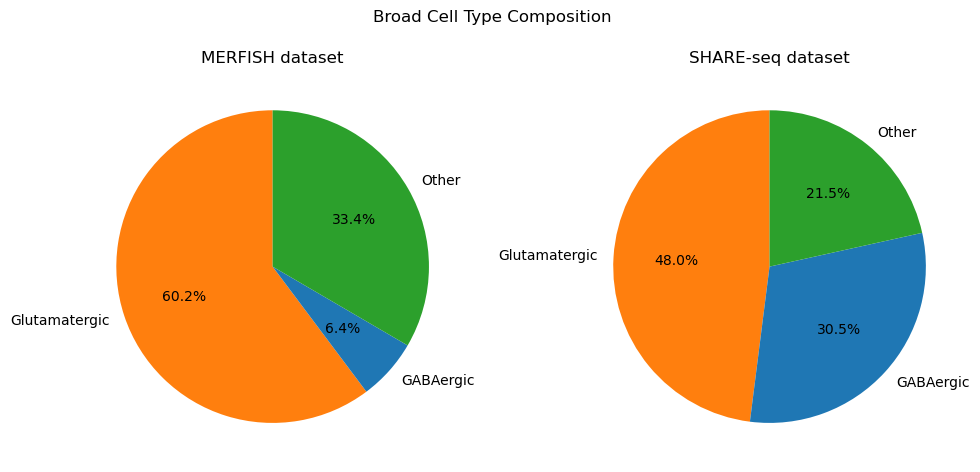

In [15]:
color_palette = [
    "#1f77b4",  # blue
    "#ff7f0e",  # orange
    "#2ca02c",  # green
    "#d62728",  # red
    "#9467bd",  # purple
    "#8c564b",  # brown
    "#e377c2",  # pink
    "#7f7f7f",  # gray
]

# Broad cell type color map
label_colors = {
    "GABAergic": color_palette[0],  # blue
    "Glutamatergic": color_palette[1],      # orange
    "Other": color_palette[2],          # green
}

# Optional: Apply to matplotlib globally (in notebooks)
def set_global_palette():
    import matplotlib.pyplot as plt
    plt.rcParams["axes.prop_cycle"] = plt.cycler(color=color_palette)


# Define consistent order and matching colors for class labels
labels = ["Glutamatergic", "GABAergic", "Other"]

colors = [label_colors[label] for label in labels]  # apply consistently

# Get normalized counts
sp_counts = sp_ad.obs["class_label"].value_counts(normalize=True).reindex(labels)
atac_counts = c_atac.obs["broad_celltype"].value_counts(normalize=True).reindex(labels)

# Plot side-by-side pie charts
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].pie(sp_counts, labels=labels, autopct="%.1f%%", startangle=90, colors=colors)
axes[0].set_title("MERFISH dataset")

axes[1].pie(atac_counts, labels=labels, autopct="%.1f%%", startangle=90, colors=colors)
axes[1].set_title("SHARE-seq dataset")

plt.suptitle("Broad Cell Type Composition")
plt.tight_layout()
#plt.savefig("../figures/ct_comp.png", dpi=300)
plt.show()